In [1]:
# code here
import cv2
import matplotlib.pyplot as plt
import numpy as np

1) Aplique nas imagens abaixo o algortimo Watershed para realizar a contagem de células. Faça tanto para  a imagem original e para a imagem gradiente

In [2]:
import sys
print(sys.executable)

d:\PDI\.venv\Scripts\python.exe


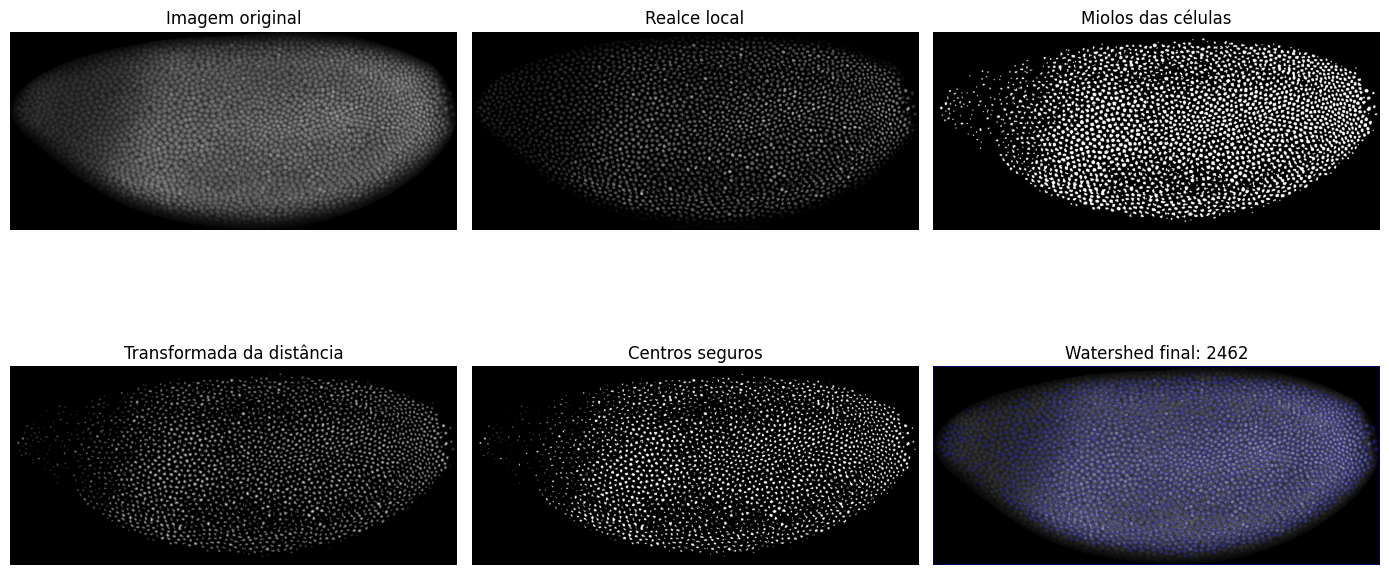

Quantidade de células: 2462


In [3]:


# Ler imagem
img1 = cv2.imread("image.jpg", cv2.IMREAD_GRAYSCALE)

# Separar fundo preto
T_fundo = 12
mascara_embriao = np.zeros_like(img1, dtype=np.uint8)
mascara_embriao[img1 > T_fundo] = 255

kernel = np.ones((3,3), np.uint8)
mascara_embriao = cv2.morphologyEx(mascara_embriao, cv2.MORPH_OPEN, kernel, iterations=1)
mascara_embriao = cv2.morphologyEx(mascara_embriao, cv2.MORPH_CLOSE, kernel, iterations=1)

# Realçar as células claras em relação à vizinhança
blur = cv2.GaussianBlur(img1, (0,0), 9)
realce = cv2.subtract(img1, blur)

# Manter só dentro do embrião
realce = cv2.bitwise_and(realce, mascara_embriao)

# Threshold para pegar os miolos claros das células
T_miolo = 8
miolos = np.zeros_like(img1, dtype=np.uint8)
miolos[realce > T_miolo] = 255

# Limpar ruído
miolos = cv2.morphologyEx(miolos, cv2.MORPH_OPEN, kernel, iterations=1)

# Distância agora em cima dos miolos/células, não do embrião todo
dist = cv2.distanceTransform(miolos, cv2.DIST_L2, 5)

# Centros seguros
T_dist = 0.35
_, sure_fg = cv2.threshold(dist, T_dist * dist.max(), 255, 0)
sure_fg = np.uint8(sure_fg)

# Fundo seguro
sure_bg = cv2.dilate(miolos, kernel, iterations=2)

# Região desconhecida
unknown = cv2.subtract(sure_bg, sure_fg)

# Marcadores
num_labels, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

# Watershed
img_color = cv2.cvtColor(img1, cv2.COLOR_GRAY2BGR)
markers = cv2.watershed(img_color, markers)

# Bordas
bordas = np.zeros_like(img1, dtype=np.uint8)
bordas[markers == -1] = 255

# Contagem
contagem = len(np.unique(markers)) - 2

# Visualização
img_result = img_color.copy()
img_result[markers == -1] = [255, 0, 0]

plt.figure(figsize=(14,8))

plt.subplot(2,3,1)
plt.imshow(img1, cmap='gray', vmin=0, vmax=255)
plt.title("Imagem original")
plt.axis("off")

plt.subplot(2,3,2)
plt.imshow(realce, cmap='gray')
plt.title("Realce local")
plt.axis("off")

plt.subplot(2,3,3)
plt.imshow(miolos, cmap='gray')
plt.title("Miolos das células")
plt.axis("off")

plt.subplot(2,3,4)
plt.imshow(dist, cmap='gray')
plt.title("Transformada da distância")
plt.axis("off")

plt.subplot(2,3,5)
plt.imshow(sure_fg, cmap='gray')
plt.title("Centros seguros")
plt.axis("off")

plt.subplot(2,3,6)
plt.imshow(cv2.cvtColor(img_result, cv2.COLOR_BGR2RGB))
plt.title(f"Watershed final: {contagem}")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Quantidade de células:", contagem)

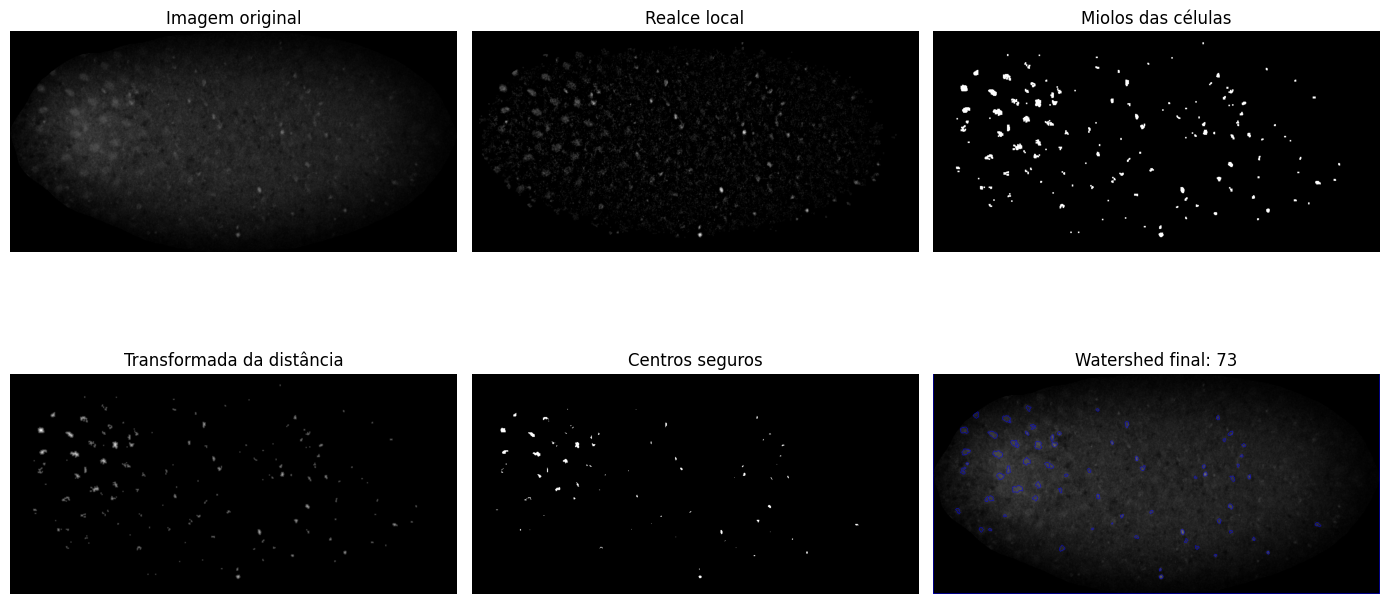

Quantidade de células: 73


In [4]:


# Ler imagem
img1 = cv2.imread("image2.jpg", cv2.IMREAD_GRAYSCALE)

# Separar fundo preto
T_fundo = 12
mascara_embriao = np.zeros_like(img1, dtype=np.uint8)
mascara_embriao[img1 > T_fundo] = 255

kernel = np.ones((3,3), np.uint8)
mascara_embriao = cv2.morphologyEx(mascara_embriao, cv2.MORPH_OPEN, kernel, iterations=1)
mascara_embriao = cv2.morphologyEx(mascara_embriao, cv2.MORPH_CLOSE, kernel, iterations=1)

# Realçar as células claras em relação à vizinhança
blur = cv2.GaussianBlur(img1, (0,0), 9)
realce = cv2.subtract(img1, blur)

# Manter só dentro do embrião
realce = cv2.bitwise_and(realce, mascara_embriao)

# Threshold para pegar os miolos claros das células
T_miolo = 8
miolos = np.zeros_like(img1, dtype=np.uint8)
miolos[realce > T_miolo] = 255

# Limpar ruído
miolos = cv2.morphologyEx(miolos, cv2.MORPH_OPEN, kernel, iterations=1)

# Distância agora em cima dos miolos/células, não do embrião todo
dist = cv2.distanceTransform(miolos, cv2.DIST_L2, 5)

# Centros seguros
T_dist = 0.35
_, sure_fg = cv2.threshold(dist, T_dist * dist.max(), 255, 0)
sure_fg = np.uint8(sure_fg)

# Fundo seguro
sure_bg = cv2.dilate(miolos, kernel, iterations=2)

# Região desconhecida
unknown = cv2.subtract(sure_bg, sure_fg)

# Marcadores
num_labels, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

# Watershed
img_color = cv2.cvtColor(img1, cv2.COLOR_GRAY2BGR)
markers = cv2.watershed(img_color, markers)

# Bordas
bordas = np.zeros_like(img1, dtype=np.uint8)
bordas[markers == -1] = 255

# Contagem
contagem = len(np.unique(markers)) - 2

# Visualização
img_result = img_color.copy()
img_result[markers == -1] = [255, 0, 0]

plt.figure(figsize=(14,8))

plt.subplot(2,3,1)
plt.imshow(img1, cmap='gray', vmin=0, vmax=255)
plt.title("Imagem original")
plt.axis("off")

plt.subplot(2,3,2)
plt.imshow(realce, cmap='gray')
plt.title("Realce local")
plt.axis("off")

plt.subplot(2,3,3)
plt.imshow(miolos, cmap='gray')
plt.title("Miolos das células")
plt.axis("off")

plt.subplot(2,3,4)
plt.imshow(dist, cmap='gray')
plt.title("Transformada da distância")
plt.axis("off")

plt.subplot(2,3,5)
plt.imshow(sure_fg, cmap='gray')
plt.title("Centros seguros")
plt.axis("off")

plt.subplot(2,3,6)
plt.imshow(cv2.cvtColor(img_result, cv2.COLOR_BGR2RGB))
plt.title(f"Watershed final: {contagem}")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Quantidade de células:", contagem)

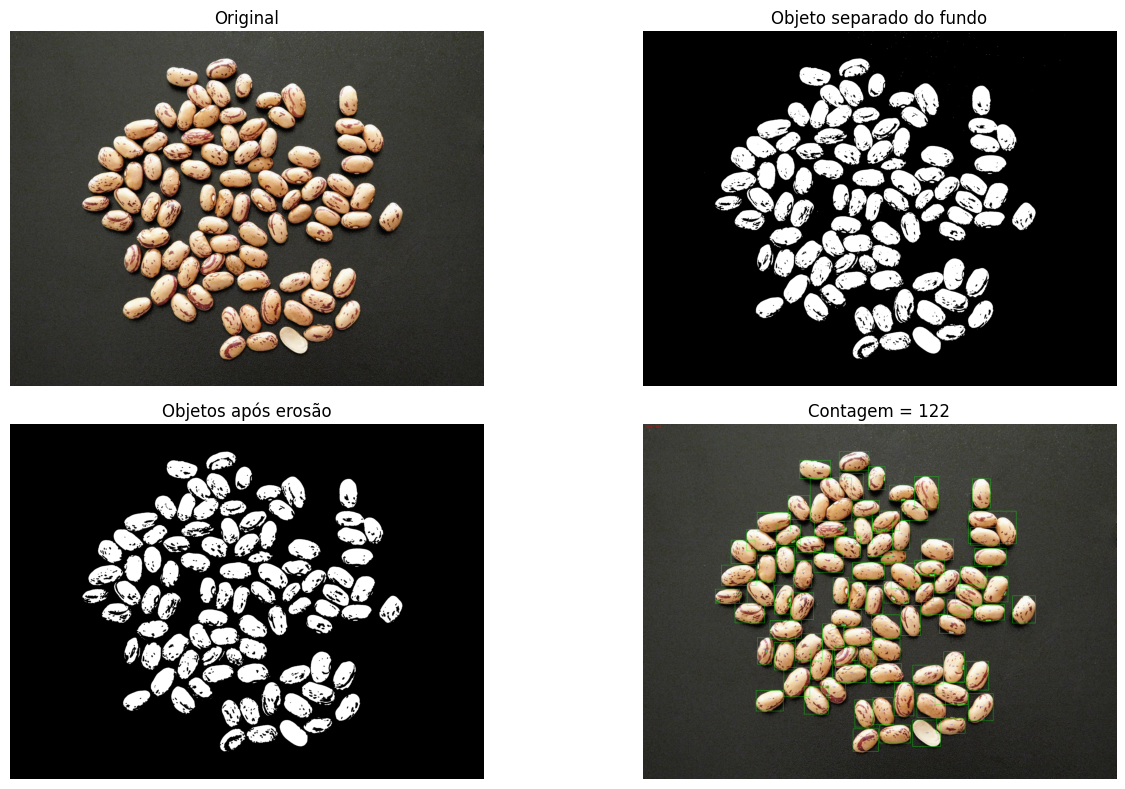

Quantidade contada: 122


In [24]:
img = cv2.imread("feijao.jpg")

if img is None:
    raise FileNotFoundError("Imagem não encontrada.")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# =========================
# 2) SEPARAR FUNDO DE OBJETO
# =========================
# Como o fundo é escuro e o feijão é claro,
# Otsu costuma funcionar bem
_, mascara = cv2.threshold(
    gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# =========================
# 3) LIMPAR RUÍDO E FECHAR BURACOS
# =========================
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

# fecha pequenos buracos internos
mascara = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, kernel, iterations=1)

# remove ruído pequeno
mascara = cv2.morphologyEx(mascara, cv2.MORPH_OPEN, kernel, iterations=1)

# =========================
# 4) ERODIR OS OBJETOS
# =========================
# A erosão encolhe os feijões.
# Se algum estiver quase encostando no outro, isso ajuda a separar.
kernel_er = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
erodida = cv2.erode(mascara, kernel_er, iterations=1)

# =========================
# 5) CONTAR COMPONENTES CONECTADOS
# =========================
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(erodida, connectivity=8)

# label 0 = fundo, então ignoramos
contagem = 0
saida = img.copy()

for i in range(1, num_labels):
    area = stats[i, cv2.CC_STAT_AREA]

    # filtro para ignorar sujeira pequena
    if area < 80:
        continue

    contagem += 1

    x = stats[i, cv2.CC_STAT_LEFT]
    y = stats[i, cv2.CC_STAT_TOP]
    w = stats[i, cv2.CC_STAT_WIDTH]
    h = stats[i, cv2.CC_STAT_HEIGHT]

    cx, cy = centroids[i]
    cx, cy = int(cx), int(cy)

    # desenha caixa
    cv2.rectangle(saida, (x, y), (x + w, y + h), (0, 255, 0), 2)

    # desenha número
    cv2.putText(
        saida,
        str(contagem),
        (cx - 10, cy),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 0, 0),
        1
    )

# texto final
cv2.putText(
    saida,
    f"Total: {contagem}",
    (20, 35),
    cv2.FONT_HERSHEY_SIMPLEX,
    1,
    (0, 0, 255),
    2
)

saida_rgb = cv2.cvtColor(saida, cv2.COLOR_BGR2RGB)

# =========================
# 6) MOSTRAR RESULTADOS
# =========================
plt.figure(figsize=(14, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(mascara, cmap="gray")
plt.title("Objeto separado do fundo")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(erodida, cmap="gray")
plt.title("Objetos após erosão")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(saida_rgb)
plt.title(f"Contagem = {contagem}")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Quantidade contada:", contagem)